# Neural Green's Operators (NGOs) for the time-dependent diffusion problem

Before running this notebook, be sure you installed the right packages according to the README.md. Running this notebook from top to bottom should give you within a few minutes a reasonably accurate trained model NGO, an animation of a true solution, projected solution and model NGO predicted solution over time, and a plot of the prediction error of the model NGO over time. For higher accuracy, set the variables 'N_samples_train'=10000, 'N_samples_val'=1000 and 'epochs'=5000. For a longer animation, set the number of time steps N_timesteps to 101.

### Imports

In [1]:
#3rd party
import torch
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

#Local
from ngo.ml.trainer import train
from ngo.ml.customlosses import *
from ngo.ml.systemnets import *
from ngo.numericalanalysis.basisfunctions import *
from ngo.ml.modelloader import *
from ngo.numericalanalysis.quadrature import *
from ngo.testproblems.timedependentdiffusion.NeuralOperator import NeuralOperator
from ngo.testproblems.timedependentdiffusion.DataModule import DataModule
from ngo.testproblems.timedependentdiffusion.manufacturedsolutions import *

/home/prins/st7/my_venv/lib/python3.13/site-packages/lightning_fabric/__init__.py:41: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.


### Data type and device

In [2]:
hparams = {}
hparams['dtype'] = torch.float64 #Model dtype
hparams['accelerator'] = 'gpu' # Can be set to 'cpu' if desired
hparams['device'] = 'cuda:2' # Can be set to 'cpu' if desired

### Training data (manufactured solutions)

In [3]:
hparams['N_samples_train'] = 100 #Number of training samples
hparams['N_samples_val'] = 10 #Number of validation samples
hparams['l_min'] = torch.tensor([0.5,0.5,0.5], dtype=hparams['dtype'], device=hparams['device']) #Minimum GRF length scale per dimension
hparams['l_max'] = torch.tensor([1,1,1], dtype=hparams['dtype'], device=hparams['device']) #Maximum GRF length scale per dimension
hparams['d'] = len(hparams['l_min']) #Number of spatial dimensions
hparams['b_theta_min'] = 1 #minimum coefficient field mean
hparams['b_theta_max'] = 1 #maximum coefficient field mean
hparams['c_theta_min'] = 0 #minimum coefficient field standard deviation
hparams['c_theta_max'] = 0.2 #maximum coefficient field standard deviation
hparams['b_u_min']  = -1 #minimum solution field mean   
hparams['b_u_max']  = 1 #maximum solution field mean
hparams['c_u_min']  = 0 #minimum solution field standard deviation
hparams['c_u_max']  = 1 #maximum solution field standard deviation
hparams['n_RBF'] = (5,5,5) #Number of basis functions per dimension for data generation

### Training settings

In [4]:
hparams['solution_loss'] = relativeL2norm_coefficients #For data NGO and model NGO. See src/ngo/ml/customlosses.py for the options
hparams['matrix_loss'] = None #Option: "relativematrixnorm" for data-free NGO
hparams['metric'] = relativeL2norm_coefficients
hparams['optimizer'] = torch.optim.Adam
hparams['learning_rate'] = 1e-3
hparams['batch_size'] = 100
hparams['epochs'] = 100 #Default for model NGO is 5000, for data NGO 20000

### Bases


In [5]:
hparams['N_i'] = (2,10,10) #Number of basis functions per dimension
hparams['p'] = (1,3,3) #Polynomial order per dimension (in case of B-spline basis)
hparams['C'] = (0,2,2) #Continuity along elements per dimension (in case of B-spline basis)
hparams['N'] = np.prod(hparams['N_i']) #Number of  basis degrees of freedom
hparams['test_bases'] = [BSplineBasis(N=hparams['N_i'][0], p=hparams['p'][0], C=hparams['C'][0], dtype=hparams['dtype'], device=hparams['device']), #basis functions in t
                         BSplineBasis(N=hparams['N_i'][1], p=hparams['p'][1], C=hparams['C'][1], dtype=hparams['dtype'], device=hparams['device']), #basis functions in x
                         BSplineBasis(N=hparams['N_i'][2], p=hparams['p'][2], C=hparams['C'][2], dtype=hparams['dtype'], device=hparams['device'])] #basis functions in y (see src/ngo/ml/basisfunctions.py for the options)
hparams['trial_bases'] = [BSplineBasis(N=hparams['N_i'][0], p=hparams['p'][0], C=hparams['C'][0], dtype=hparams['dtype'], device=hparams['device']), #basis functions in t
                         BSplineBasis(N=hparams['N_i'][1], p=hparams['p'][1], C=hparams['C'][1], dtype=hparams['dtype'], device=hparams['device']), #basis functions in x
                         BSplineBasis(N=hparams['N_i'][2], p=hparams['p'][2], C=hparams['C'][2], dtype=hparams['dtype'], device=hparams['device'])] #basis functions in y (see src/ngo/ml/basisfunctions.py for the options)
hparams['Dt'] = 0.01 #Time step size

### Quadrature

In [6]:
hparams['quadrature'] = 'Gauss-Legendre' #Quadrature rule, either "Gauss-Legendre" or "uniform" (for FNO)
hparams['n_elements'] = (1,3,3) #Number of elements of the quadrature grid
hparams['Q'] = (2,99,99) #Number of quadrature points per dimension (for all elements, not per element)
hparams['quadrature_L'] = 'Gauss-Legendre' #Loss quadrature rule, either "Gauss-Legendre" or "uniform" (for FNO)
hparams['n_elements_L'] = (1,3,3) #Number of elements of the loss quadrature grid
hparams['Q_L'] = (2,99,99) #Number of loss quadrature points per dimension (for all elements, not per element)

### System net

In [7]:
hparams['modeltype'] = 'model NGO' #Options: "NN" for bare NN, "DeepONet", "VarMiON", "data NGO", "model NGO"
hparams['systemnet'] = CNN #See src/ngo/ml/systemnets.py for the options
hparams['N_w'] = 30000 #Number of trainable parameters (upper bound, not exact)
hparams['bias'] = False
hparams['skipconnections'] = True #In case of a symmetric CNN -> U-Net
hparams['kernel_sizes'] = [2,2,5,10,10,5,2,2] #In case of a CNN. See paper appendix for kernel sizes for all different models
# hparams['kernel_sizes'] = [(1,1,1), (1,1,1), (1,2,2), (2,5,5), (5,5), (2,2), (1,1), (20,20)] #In case of a CNN. See paper appendix for kernel sizes for all different models
hparams['bottleneck_size'] = 20 #MLP bottleneck size in case of a CNN (uses an MLP connection in the bottleneck)
hparams['outputactivation'] = nn.Tanhshrink() #Set to None for models other than model NGO. For the systemnet. Hidden layer activations are ReLU by default

### Additional inductive bias

In [8]:
hparams['output_coefficients'] = True #Whether the NN outputs coefficients (True) or values at quadrature points (False)
hparams['project_materialparameters'] = True
hparams['Neumannseries'] = True #Whether to use Neumann series expansion (only for model NGOs and data-free NGOs)
hparams['Neumannseries_order'] = 1 #Order of the Neumann series expansion (only for model NGOs and data-free NGOs)
hparams['scaling_equivariance'] = False #Whether to use scaling equivariance (only for NGOs)
hparams['Mnorm_scaling'] = False #Whether to scale the system matrix norm during training (only for data NGO)
hparams['Mnorm_max'] = 0.8 #Target maximum system matrix norm (only for data NGO)
hparams['tol'] = 1e-3 #Power iteration tolerance for estimating the system matrix norm (only for data NGO)
hparams['max_iterations'] = 1000 #Power iteration max. number of iterations for estimating the system matrix norm (only for data NGO)
hparams['alpha'] = 0 #Dissipation parameter (set to 0 by default)
hparams['gamma_stabilization'] = 100 #Stabilization constant for the system matrix
hparams['massconservation'] = False #Whether to enforce mass conservation
hparams['dissipation'] = False #Whether to enforce a dissipation
hparams['stabilization_in_massconservation'] = False #Whether to include the stabilization term in the mass conservation constraint

### Directory to save the model and tensorboard log, model name

In [9]:
logdir = './nnlogs' #Location for the tensorboard log files
sublogdir = 'tdd' #Folder name in the "nnlogs" directory
label = 'ngo' #Give your model a name
hparams['logdir'] = logdir+'/'+sublogdir+'/'+label
hparams['label'] = label

### Train the model

In [10]:
train(NeuralOperator, DataModule, hparams, logdir, sublogdir, label)

Generating input and output functions...


/data/storage7/prins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:53: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.b = torch.tensor(b, dtype=self.dtype, device=self.device)
/data/storage7/prins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:54: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.c = torch.tensor(c, dtype=self.dtype, device=self.device)


Discretizing input functions...
Assembling F...
Assembling d...
Calculating conserved quantity...
Discretizing output function...


/home/prins/st7/my_venv/lib/python3.13/site-packages/lightning_fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/prins/st7/my_venv/lib/python3.13/site-packages ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/data/storage7/prins/git/ngo-pde-gk/src/ngo/testproblems/timedependentdiffusion/DataModule.py:122: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.F = torch.tensor(self.F, dtype=self.hparams['dtype'])
/data/storage7/prins/git/ngo-pde-gk/src/ngo/testproblems/timedependentdiffusion/DataModule.py:123: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clon

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation metric: 0.0019134108876724728


Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=100` reached.


Validation metric: 0.0019010429852689024
Training time: 7.786103s


### Disable torch gradient tracking for memory/speed efficiency

In [1]:
torch.set_grad_enabled(False)

NameError: name 'torch' is not defined

### Load the model


In [28]:
projection = loadmodelfromlabel(model=NeuralOperator, label=label, logdir=logdir, sublogdir=sublogdir, device=hparams['device'])
projection.hparams['modeltype'] = 'projection'
projection.__init__(projection.hparams)

modelNGO = loadmodelfromlabel(model=NeuralOperator, label=label, logdir=logdir, sublogdir=sublogdir, device=hparams['device'])

models = {'Projection': projection,
             'Model NGO': modelNGO}

### Animation of true, projected and predicted solutions

In [29]:
tau = 0.1 #time scale of manufactured solution test sample
l = 0.1 #length scale of manufactured solution test sample
N_timesteps = 101 #number of time steps
t_values = np.linspace(0, (N_timesteps-1)*projection.hparams['Dt'], N_timesteps)  # Time steps for the animation

<>:96: SyntaxWarning: invalid escape sequence '\m'
<>:96: SyntaxWarning: invalid escape sequence '\m'
/data/storage7/prins/temp/ipykernel_1876068/2868701245.py:96: SyntaxWarning: invalid escape sequence '\m'
  ax.set_title('Projection $u^{\mathrm{p}}$', fontsize=size_title)


0.0
0.0
0.01
0.02
0.03
0.04
0.05
0.06
0.07
0.08
0.09
0.1
0.11
0.12
0.13
0.14
0.15
0.16
0.17
0.18
0.19
0.2
0.21
0.22
0.23
0.24
0.25
0.26
0.27
0.28
0.29
0.3
0.31
0.32
0.33
0.34
0.35000000000000003
0.36
0.37
0.38
0.39
0.4
0.41000000000000003
0.42
0.43
0.44
0.45
0.46
0.47000000000000003
0.48
0.49
0.5
0.51
0.52
0.53
0.54
0.55
0.56
0.5700000000000001
0.58
0.59
0.6
0.61
0.62
0.63
0.64
0.65
0.66
0.67
0.68
0.6900000000000001
0.7000000000000001
0.71
0.72
0.73
0.74
0.75
0.76
0.77
0.78
0.79
0.8
0.81
0.8200000000000001
0.8300000000000001
0.84
0.85
0.86
0.87
0.88
0.89
0.9
0.91
0.92
0.93
0.9400000000000001
0.9500000000000001
0.96
0.97
0.98
0.99
1.0
0.0


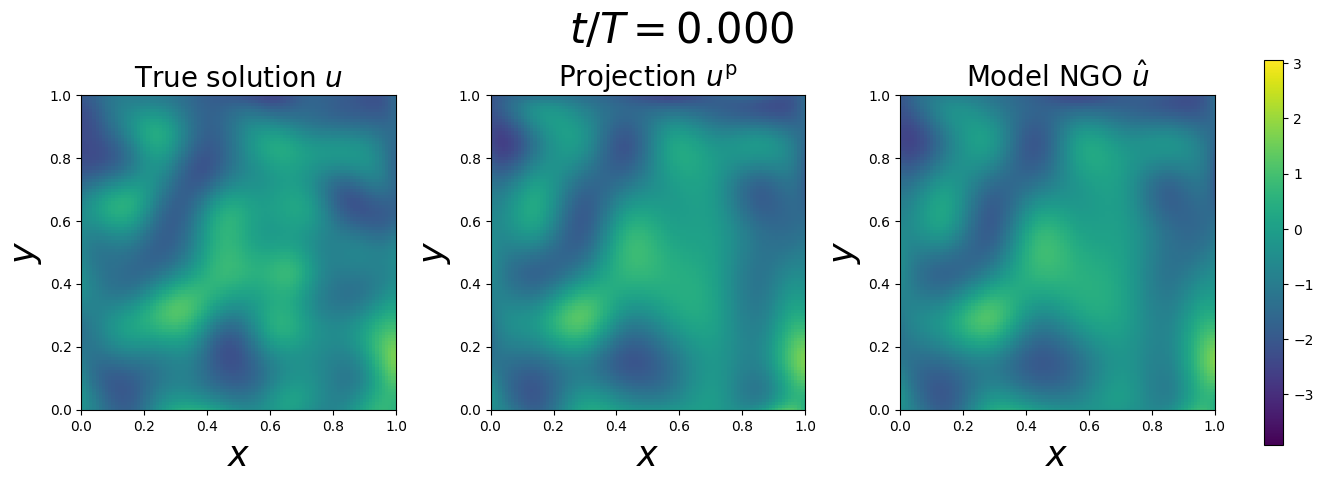

In [30]:
# Set number of samples to 1 for animation generation
N_samples = 1

# Quadrature points and weights
w_t, xi_t = UniformQuadrature(Q=1, dtype=projection.hparams['dtype'], device=projection.hparams['device']).compute_quadrature()
w_x, xi_x = UniformQuadrature(Q=100, dtype=projection.hparams['dtype'], device=projection.hparams['device']).compute_quadrature()
w_y, xi_y = UniformQuadrature(Q=100, dtype=projection.hparams['dtype'], device=projection.hparams['device']).compute_quadrature()
w_t = w_t*projection.hparams['Dt']
xi_t_0 = xi_t*projection.hparams['Dt']
W = w_t, w_x, w_y
X = xi_t_0, xi_x, xi_y
    
# Set length scales for the manufactured solutions
l = torch.tensor([tau,l,l], dtype=hparams['dtype'], device=hparams['device'])
# Generate manufactured solution test sample   
manufacturedsolutions = ManufacturedSolutions(N_samples,
                                            hparams['d'],
                                            l,
                                            l,
                                            hparams['b_u_min'],
                                            hparams['b_u_max'],
                                            hparams['c_u_min'],
                                            hparams['c_u_max'],
                                            hparams['b_theta_min'],
                                            hparams['b_theta_max'],
                                            hparams['c_theta_min'],
                                            hparams['c_theta_max'],
                                            hparams['device'],
                                            hparams['dtype'],
                                            hparams['n_RBF'])
theta = manufacturedsolutions.theta
f = manufacturedsolutions.f
eta_y0 = manufacturedsolutions.eta_y0
eta_yL = manufacturedsolutions.eta_yL
g_x0 = manufacturedsolutions.g_x0
g_xL = manufacturedsolutions.g_xL
u = manufacturedsolutions.u
u0 = manufacturedsolutions.u0

# Animation parameters
size_title = 20
size_ticklabels = 15
size_axeslabels = 25

# Compute initial fields
u_exact = u.forward(X)
u_proj = projection.simforward(theta, f, eta_y0, eta_yL, g_x0, g_xL, u0, X, u)
u_hat_modelNGO = modelNGO.simforward(theta, f, eta_y0, eta_yL, g_x0, g_xL, u0, X, u)

# Create meshgrid for contour plots
X_mesh, Y_mesh = torch.meshgrid(X[1], X[2], indexing='ij')

# Evaluate min and max for consistent color scaling
X_all = torch.tensor(t_values, dtype=hparams['dtype'], device=hparams['device']), xi_x, xi_y
u_all_true = u.forward(X_all)
u_min = torch.amin(u_all_true)
u_max = torch.amax(u_all_true)

import matplotlib.colors as mcolors
shared_norm = mcolors.Normalize(vmin=float(u_min), vmax=float(u_max))

# Meshgrid (numpy for pcolormesh)
X_mesh, Y_mesh = torch.meshgrid(X[1], X[2], indexing='ij')
Xn = X_mesh.cpu().numpy()
Yn = Y_mesh.cpu().numpy()

fig, axs = plt.subplots(1, 3, figsize=(16, 5), facecolor='none')
for ax in axs:
    ax.set_facecolor('none')
fig.subplots_adjust(wspace=0.3)

# Initial fields
u_exact = u.forward(X)
u_proj = projection.simforward(theta, f, eta_y0, eta_yL, g_x0, g_xL, u0, X, u)
u_hat_modelNGO = modelNGO.simforward(theta, f, eta_y0, eta_yL, g_x0, g_xL, u0, X, u)

# Create pcolormesh objects
ax = axs[0]
pcm_true = ax.pcolormesh(Xn, Yn, u_exact[0,0].cpu().numpy(), shading='auto', norm=shared_norm)
ax.ticklabel_format(style='sci', scilimits=[-3,3])
ax.set_xlabel(r'$x$', fontsize=size_axeslabels)
ax.set_ylabel(r'$y$', fontsize=size_axeslabels)
ax.set_xlim(0,1)
ax.set_ylim(0,1)
ax.set_aspect('equal')
ax.set_title('True solution $u$', fontsize=size_title)# ax.set_aspect('equal')

ax = axs[1]
pcm_proj = ax.pcolormesh(Xn, Yn, u_proj[0,0].cpu().numpy(), shading='auto', norm=shared_norm)
ax.ticklabel_format(style='sci', scilimits=[-3,3])
ax.set_xlabel(r'$x$', fontsize=size_axeslabels)
ax.set_ylabel(r'$y$', fontsize=size_axeslabels)
ax.set_xlim(0,1)
ax.set_ylim(0,1)
ax.set_aspect('equal')
ax.set_title('Projection $u^{\mathrm{p}}$', fontsize=size_title)

ax = axs[2]
pcm_hat  = ax.pcolormesh(Xn, Yn, u_hat_modelNGO[0,0].detach().cpu().numpy(), shading='auto', norm=shared_norm)
ax.ticklabel_format(style='sci', scilimits=[-3,3])
ax.set_xlabel(r'$x$', fontsize=size_axeslabels)
ax.set_ylabel(r'$y$', fontsize=size_axeslabels)
ax.set_xlim(0,1)
ax.set_ylim(0,1)
ax.set_aspect('equal')
ax.set_title('Model NGO $\\hat{u}$', fontsize=size_title)

# Shared colorbar
cbar = fig.colorbar(pcm_true, ax=axs, fraction=0.046, pad=0.04)
# cbar.set_label('Value')

def update(t):
    print(t)
    xi_t = modelNGO.t_0 + xi_t_0
    X_local = (xi_t, xi_x, xi_y)

    u_exact_t = u.forward(X_local)
    u_proj_t = projection.simforward(theta, f, eta_y0, eta_yL, g_x0, g_xL, u0, X_local, u)
    u_hat_t  = modelNGO.simforward(theta, f, eta_y0, eta_yL, g_x0, g_xL, u0, X_local, u)

    pcm_true.set_array(u_exact_t[0,0].cpu().numpy().ravel())
    pcm_proj.set_array(u_proj_t[0,0].cpu().numpy().ravel())
    pcm_hat.set_array(u_hat_t[0,0].detach().cpu().numpy().ravel())

    plt.suptitle(f'$t/T={t:.3f}$', fontsize=30)

    # projection.time_step()
    # modelNGO.time_step()

ani = FuncAnimation(fig, update, frames=t_values, repeat=False)

#Save or display animation
# in GIF format
# ani.save('animation_timestepping_NGO.gif', writer='pillow', fps=10, savefig_kwargs={'transparent': True})

# Or in MP4 format
ani.save('animation_timestepping_NGO.mp4', writer='ffmpeg', fps=10, savefig_kwargs={'transparent': True})

### Plot of errors over time


In [35]:
# Parameters
N_samples = 100 # Number of test samples
N_timesteps = 101 # Number of time steps
tau = 0.1 # time scale
l = 0.1 # length scale

In [36]:
# Load models again to reset time steps
projection = loadmodelfromlabel(model=NeuralOperator, label=label, logdir=logdir, sublogdir=sublogdir, device=hparams['device'])
projection.hparams['modeltype'] = 'projection'
projection.__init__(projection.hparams)

modelNGO = loadmodelfromlabel(model=NeuralOperator, label=label, logdir=logdir, sublogdir=sublogdir, device=hparams['device'])

models = {'Projection': projection,
             'Model NGO': modelNGO}

Projection
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
Model NGO
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100


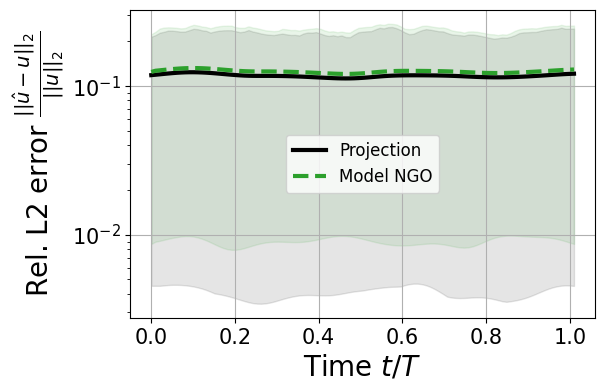

: 

In [ ]:
# Confidence interval parameters
alpha = 0.05
q_low = alpha/2
q_high = 1 - q_low

# Initialize arrays to store errors
L2_scaled_avg = np.zeros((len(models),N_timesteps))
yerr = np.zeros((len(models),2,N_timesteps))

# Quadrature points and weights
w_t, xi_t = GaussLegendreQuadrature(Q=2, n_elements=1, dtype=projection.hparams['dtype'], device=projection.hparams['device']).compute_quadrature()
w_x, xi_x = GaussLegendreQuadrature(Q=99, n_elements=3, dtype=projection.hparams['dtype'], device=projection.hparams['device']).compute_quadrature()
w_y, xi_y = GaussLegendreQuadrature(Q=99, n_elements=3, dtype=projection.hparams['dtype'], device=projection.hparams['device']).compute_quadrature()
w_t = w_t*projection.hparams['Dt']
xi_t = xi_t*projection.hparams['Dt']
W = w_t.detach().cpu(), w_x.detach().cpu(), w_y.detach().cpu()
X = xi_t, xi_x, xi_y
xi_t_0 = torch.clone(xi_t)

# Set length scales for the manufactured solutions
l = torch.tensor([tau,l,l], dtype=projection.hparams['dtype'], device=projection.hparams['device'])
# Generate manufactured solutions
manufacturedsolutions = ManufacturedSolutions(N_samples=N_samples, 
                                                d=len(l), 
                                                l_min=l, l_max=l, 
                                                b_u_min=projection.hparams['b_u_min'],
                                                b_u_max=projection.hparams['b_u_max'],
                                                c_u_min=projection.hparams['c_u_min'],
                                                c_u_max=projection.hparams['c_u_max'],
                                                b_theta_min=projection.hparams['b_theta_min'], #1
                                                b_theta_max=projection.hparams['b_theta_max'], #1
                                                c_theta_min=projection.hparams['c_theta_min'], #0
                                                c_theta_max=projection.hparams['c_theta_max'], #0
                                                device=projection.hparams['device'],
                                                dtype=projection.hparams['dtype'],
                                                n_RBF=None)
theta = manufacturedsolutions.theta
f = manufacturedsolutions.f
eta_y0 = manufacturedsolutions.eta_y0
eta_yL = manufacturedsolutions.eta_yL
g_x0 = manufacturedsolutions.g_x0
g_xL = manufacturedsolutions.g_xL
u0 = manufacturedsolutions.u0
u = manufacturedsolutions.u
m=0
for model in models:
    print(str(model))
    models[str(model)].timestep = 0
    # Initialize quadrature points in time
    xi_t = xi_t_0
    X = (xi_t, xi_x, xi_y)
    for i in range(N_timesteps):
        print(i)
        u_exact = u.forward(X).detach().cpu()
        u_hat = models[str(model)].simforward(theta, f, eta_y0, eta_yL, g_x0, g_xL, u0, X, u).detach().cpu()
        L2_scaled_array = relativeL2norm_set(W, u_hat, u_exact)
        L2_scaled_avg[m,i] = torch.mean(L2_scaled_array)
        q_l = torch.quantile(L2_scaled_array, q_low)
        q_h = torch.quantile(L2_scaled_array, q_high)
        yerr[m,:,i] = torch.tensor([q_l, q_h])
        # Advance quadrature points in time
        xi_t = models[str(model)].t_0 + xi_t_0
        X = (xi_t, xi_x, xi_y)
    m+=1

# Time values for plotting
t_values = np.linspace(0,N_timesteps*projection.hparams['Dt'],N_timesteps)

# Plotting parameters
size_title = 20
size_ticklabels = 15
size_axeslabels = 20
colors = ['black', 'C2']
linestyles = ['-', '--']

# Plot errors over time
fig, ax = plt.subplots(1,1, figsize=(6, 4))
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.4, hspace=0.4)
plots = []
m=0
ax.tick_params(axis='both', labelsize=size_ticklabels)
ax.set_xlabel(r'Time $t/T$', fontsize=size_axeslabels)
ax.set_ylabel(r'Rel. L2 error $\frac{||\hat{u}-u||_2}{||u||_2}$', fontsize=size_axeslabels)
ax.set_yscale('log')
ax.grid()
for model in models:
    plots.append(ax.plot(t_values, L2_scaled_avg[m], label=str(model), color=colors[m], linestyle=linestyles[m], linewidth=3)[0])
    ax.fill_between(t_values, yerr[m,0,:], yerr[m,1,:], alpha=0.1, color=colors[m])
    m+=1
plt.legend(fontsize=12)
plt.savefig("errorsovertime.png", bbox_inches='tight')#, transparent=True)
plt.show()